<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 💬 用 Slack 做人工审批：interrupt → 通知 → 按钮 → resume

**一句话定位**：图里 `interrupt()` 暂停并持久化 → 把审批消息（带按钮）发到 Slack → 人点按钮 → Slack 回调你的服务 → `Command(resume=…)` 续跑。
> 暂停/续跑逻辑和重复发送坑已在本机 langgraph 1.2 实测（用假 Slack 客户端）；`slack_bolt` / Slack 网络部分未联网实测，按官方 API 写。

</div>

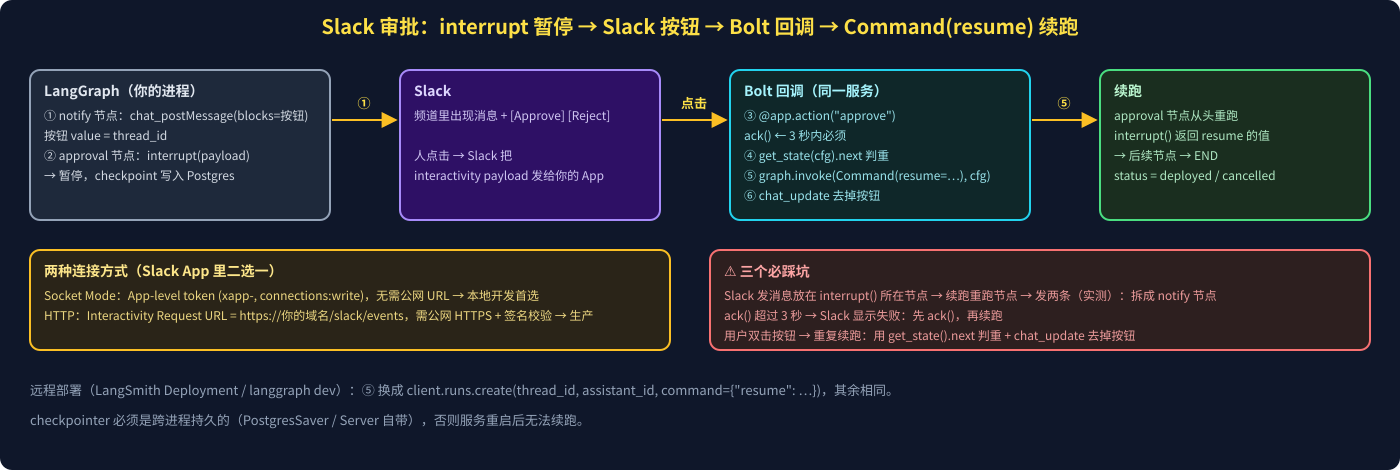

In [ ]:
from IPython.display import SVG
SVG(filename="assets/14_slack_hitl.svg")

### 1️⃣ 一次性配置 Slack App

| 项 | 做法 |
|---|---|
| 创建 | api.slack.com/apps → Create New App |
| Bot 权限 | OAuth & Permissions → Bot Token Scopes：`chat:write`（需要进私有频道再加 `groups:write`）；安装到 workspace，得到 `SLACK_BOT_TOKEN`（`xoxb-`） |
| 交互 | Interactivity & Shortcuts → **On**（按钮点击必须开） |
| Socket Mode（开发） | 开启 Socket Mode，生成 App-level token（`xapp-`，scope `connections:write`）→ `SLACK_APP_TOKEN`；Interactivity 无需填 URL |
| HTTP（生产） | Interactivity Request URL 填 `https://域名/slack/events`；记下 Signing Secret → `SLACK_SIGNING_SECRET` |
| 频道 | 邀请 bot 进频道（`/invite @bot`），拿到频道 ID（`C…`） |

```bash
pip install slack_bolt slack_sdk langgraph langgraph-checkpoint-postgres
```

### 2️⃣ 图：notify 与 approval 必须分两个节点

In [ ]:
import os
from typing_extensions import TypedDict
from slack_sdk import WebClient
from langgraph.checkpoint.memory import InMemorySaver      # 生产换 PostgresSaver
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt

slack = WebClient(token=os.environ["SLACK_BOT_TOKEN"])
CHANNEL = "C0123456789"

class State(TypedDict):
    branch: str
    slack_ts: str
    status: str

def notify(state: State, config):                         # ① 只发通知，没有 interrupt
    thread_id = config["configurable"]["thread_id"]
    def button(text, action_id, style):
        return {"type": "button", "text": {"type": "plain_text", "text": text},
                "action_id": action_id, "style": style,
                "value": thread_id}                       # value 带上 thread_id，回调靠它找到这条 thread
    resp = slack.chat_postMessage(
        channel=CHANNEL,
        text=f"Deploy {state['branch']}?",                # 通知预览 / 无障碍文本
        blocks=[
            {"type": "section", "text": {"type": "mrkdwn", "text": f"*Deploy `{state['branch']}` to production?*"}},
            {"type": "actions", "elements": [button("Approve", "approve", "primary"),
                                             button("Reject", "reject", "danger")]},
        ],
    )
    return {"slack_ts": resp["ts"]}

def approval(state: State):                               # ② 只 interrupt
    decision = interrupt({"kind": "deploy_approval", "branch": state["branch"]})
    return {"status": "deployed" if decision["approved"] else "cancelled"}

builder = StateGraph(State)
builder.add_node("notify", notify)
builder.add_node("approval", approval)
builder.add_edge(START, "notify")
builder.add_edge("notify", "approval")
builder.add_edge("approval", END)
graph = builder.compile(checkpointer=InMemorySaver())

# 触发：thread_id 自己定（业务 ID 最好，如 deploy-42），返回值里带 "__interrupt__" 表示已暂停
cfg = {"configurable": {"thread_id": "deploy-42"}}
graph.invoke({"branch": "main"}, cfg)

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**为什么拆两个节点**：续跑时节点**从头重跑**。若把 `chat_postMessage` 和 `interrupt()` 放进同一节点，续跑那一刻会**再发一条 Slack 消息**（实测：同节点 2 条，拆开后 1 条）。凡是有副作用的代码都放在 `interrupt()` 所在节点之前的**独立节点**里。

</div>

### 3️⃣ Slack 回调：Bolt 监听按钮 → `Command(resume=…)`

In [ ]:
from slack_bolt import App
from slack_bolt.adapter.socket_mode import SocketModeHandler

app = App(token=os.environ["SLACK_BOT_TOKEN"],
          signing_secret=os.environ.get("SLACK_SIGNING_SECRET"))     # HTTP 模式下 Bolt 自动验签

def decide(approved: bool, body: dict, client):
    action = body["actions"][0]
    thread_id = action["value"]
    cfg = {"configurable": {"thread_id": thread_id}}

    if not graph.get_state(cfg).next:                     # 判重：已无待执行节点 = 已处理过
        return
    graph.invoke(Command(resume={"approved": approved, "by": body["user"]["id"]}), cfg)

    client.chat_update(                                   # 去掉按钮，改成结果，防止再点
        channel=body["channel"]["id"], ts=body["message"]["ts"], blocks=[],
        text=f"{'✅ Approved' if approved else '❌ Rejected'} by <@{body['user']['id']}>",
    )

@app.action("approve")
def on_approve(ack, body, client):
    ack()                                                 # 必须 3 秒内 ack，再做重活
    decide(True, body, client)

@app.action("reject")
def on_reject(ack, body, client):
    ack()
    decide(False, body, client)

if __name__ == "__main__":
    SocketModeHandler(app, os.environ["SLACK_APP_TOKEN"]).start()      # 开发：Socket Mode
    # app.start(port=3000)                                             # 生产：HTTP，Request URL → /slack/events

| 回调要点 | 说明 |
|---|---|
| payload 来源 | Bolt 已解析：`body["actions"][0]["action_id" / "value"]`、`body["user"]["id"]`、`body["channel"]["id"]`、`body["message"]["ts"]` |
| 找回 thread | 按钮 `value`（≤ 2000 字符）放 `thread_id`；也可放数据库里的审批单 ID |
| 判重（实测） | 续跑后 `get_state(cfg).next == ()`，第二次点击直接返回 |
| 谁点的 | `resume` 值里带 `body["user"]["id"]`，节点里可校验权限 / 写审计 |
| 耗时 | `graph.invoke` 若很长（继续跑后续 LLM / 部署），在线程池或任务队列里跑，别阻塞 ack |

### 4️⃣ 远程部署版：用 LangGraph SDK 续跑

图跑在 `langgraph dev` / LangSmith Deployment 上时，回调只换第 ⑤ 步：

In [ ]:
from langgraph_sdk import get_client

lg = get_client(url=os.environ.get("LANGGRAPH_URL", "http://127.0.0.1:2024"))

async def resume_remote(thread_id: str, approved: bool, user_id: str):
    state = await lg.threads.get_state(thread_id)
    if not state["next"]:                                  # 判重
        return
    await lg.runs.create(                                  # 后台续跑，立即返回
        thread_id, "agent",                                # "agent" = langgraph.json 里的 graph 名
        command={"resume": {"approved": approved, "by": user_id}},
    )

# 触发审批：await lg.runs.create(thread_id, "agent", input={"branch": "main"}, config={...})
# 暂停通知：图里 notify 节点照常发 Slack；Server 自带 Postgres checkpointer，无需自己配

### 5️⃣ 手动验签（HTTP 模式不用 Bolt 时）

In [ ]:
import hashlib
import hmac
import time

def verify_slack(signing_secret: str, timestamp: str, raw_body: str, signature: str) -> bool:
    if abs(time.time() - int(timestamp)) > 300:           # 超过 5 分钟：防重放
        return False
    base = f"v0:{timestamp}:{raw_body}"                   # raw_body 必须是未解析的原始字节串
    mine = "v0=" + hmac.new(signing_secret.encode(), base.encode(), hashlib.sha256).hexdigest()
    return hmac.compare_digest(mine, signature)           # 请求头：X-Slack-Request-Timestamp / X-Slack-Signature

# 按钮点击的 body 是 form 编码：payload=<url-encoded JSON>  →  json.loads(parse_qs(raw_body)["payload"][0])

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**踩坑清单**

| 坑 | 后果 / 做法 |
|---|---|
| 通知与 `interrupt()` 同节点 | 续跑重发（实测）→ 拆节点 |
| 超过 3 秒才 `ack()` | Slack 显示"操作失败" → 先 `ack()` 再干活 |
| 重复点击 | 判 `get_state().next`；`chat_update` 清掉按钮 |
| `InMemorySaver` 做生产 | 进程重启丢暂停状态 → `PostgresSaver` / Server |
| 回调进程拿不到 `graph` | 回调与图必须能访问同一 checkpointer：同进程，或走 SDK 远程 |
| 没人点 | 加超时：定时任务扫 `next` 非空且超时的 thread，`resume={"approved": False}` 或提醒 |
| 谁都能点 | `resume` 前校验 `body["user"]["id"]` 是否在审批人名单 |
| 想在 Slack 里回文字而非按钮 | 订阅 `message` 事件 + 用 thread_ts 映射回 thread_id，`resume=消息文本` |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：**`notify` 节点发带按钮的 Slack 消息（按钮 value = thread_id）→ `approval` 节点 `interrupt()` → Bolt 的 `@app.action` 里先 `ack()`、判重、再 `graph.invoke(Command(resume=…), cfg)`**；副作用拆出 `interrupt()` 节点，checkpointer 要持久化。

</div>